# Day 1 Project: Your First Crop Disease Classifier (Kaggle version)

**Setup steps before running any cell -- do these on kaggle.com first:**

1. Go to https://www.kaggle.com/code and click **New Notebook**.
2. Copy the contents of each cell below into your new Kaggle notebook (or upload this `.ipynb` file directly using **File -> Upload Notebook** on that page).
3. On the right-hand sidebar of the notebook editor, click **Add Input** (or **+ Add Data**), search for `plantdisease`, and add the dataset by **emmarex** titled *PlantVillage Dataset*. This attaches the data directly -- no download, no login step, no API key.
4. Still on the right-hand sidebar, open **Settings** (or the three dots menu) and set **Accelerator** to **GPU T4 x2** (or whichever GPU option is available). This gives you free GPU training.
5. Run cells top to bottom using **Shift+Enter**.

That's the entire setup -- Kaggle notebooks already come with Python, PyTorch, and everything else preinstalled.

## Step 1: Imports and device check

In [2]:
import os
import glob
import shutil
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
# If this prints 'cpu', go to the notebook's Settings/accelerator menu, choose a GPU, and re-run this cell.

Using device: cuda


## Step 2: Find the dataset
Kaggle mounts any dataset you 'Add' under `/kaggle/input/`. We search for it automatically so you don't have to guess the exact path.

In [3]:
print('Contents of /kaggle/input:', os.listdir('/kaggle/input'))

# Search for a folder that contains the PlantVillage class directories
candidates = glob.glob('/kaggle/input/**/PlantVillage', recursive=True)
if not candidates:
    # Some versions of this dataset skip the 'PlantVillage' wrapper folder -- search one level deeper
    candidates = [p for p in glob.glob('/kaggle/input/*/*') if os.path.isdir(p) and any('Tomato' in c for c in os.listdir(p))]

assert candidates, 'Could not auto-find the dataset. Check the folder names printed above and set `root` manually below.'
root = candidates[0]
print('Using dataset root:', root)
print('Classes found:', sorted(os.listdir(root))[:10], '... and more')

Contents of /kaggle/input: ['datasets']
Using dataset root: /kaggle/input/datasets/emmarex/plantdisease/PlantVillage
Classes found: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot'] ... and more


## Step 3: Pick a small, manageable slice to start with
We'll use **5 tomato classes** as a first project -- exactly matching Week 3-4 of your roadmap. You can widen this to more crops/classes later.

Kaggle's input data is **read-only**, so we copy just the classes we want into `/kaggle/working/` (the writable folder) before training.

In [16]:
# << CHANGED HERE >> full list of all 15 classes across Pepper, Potato, Tomato
TARGET_CLASSES = [
    'Pepper__bell___Bacterial_spot',
    'Pepper__bell___healthy',
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy',
    'Tomato_Bacterial_spot',
    'Tomato_Early_blight',
    'Tomato_Late_blight',
    'Tomato_Leaf_Mold',
    'Tomato_Septoria_leaf_spot',
    'Tomato_Spider_mites_Two_spotted_spider_mite',
    'Tomato__Target_Spot',
    'Tomato__Tomato_YellowLeaf__Curl_Virus',
    'Tomato__Tomato_mosaic_virus',
    'Tomato_healthy',
]

# << CHANGED HERE >> since we're using every class in the dataset, we skip copying
# into a separate folder and just point directly at the original data -- saves time and disk space.
SUBSET_DIR = root

## Step 4: Prepare the data for training
Neural networks need images resized to a fixed size and turned into numbers (tensors). We split into a **training set** (used to learn) and a **validation set** (used to check progress on images the model hasn't memorized).

In [17]:
IMG_SIZE = 224  # standard input size for MobileNetV2

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),      # simple data augmentation
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],  # standard ImageNet normalization
                          std=[0.229, 0.224, 0.225]),
])

full_dataset = datasets.ImageFolder(SUBSET_DIR, transform=transform)
class_names = full_dataset.classes
print('Classes found:', class_names)

val_size = int(0.2 * len(full_dataset))
train_size = len(full_dataset) - val_size
train_ds, val_ds = random_split(full_dataset, [train_size, val_size])
print(f'Training images: {train_size}, Validation images: {val_size}')

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)

Classes found: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Training images: 16511, Validation images: 4127


## Step 5: Build the model using transfer learning
We don't train a network from scratch -- that needs far more data and time than we have. Instead we take **MobileNetV2**, a network already trained on millions of general images, and retrain just its final layer to recognize our 5 tomato classes. This is called **transfer learning**.

In [18]:
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# Freeze all the pretrained layers so we don't wreck what they already learned
for param in model.parameters():
    param.requires_grad = False

# Replace the final classification layer with one matching our 5 classes
num_classes = len(class_names)
model.classifier[1] = nn.Linear(model.last_channel, num_classes)

model = model.to(device)
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=15, bias=True)
)


## Step 6: Train the model
An **epoch** = one full pass through all training images. Since we only retrained the last layer, this should take just a few minutes on a Kaggle GPU.

In [20]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)

EPOCHS = 12
history = {'train_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    train_loss = running_loss / train_size

    # Check accuracy on the validation set (images the model hasn't trained on)
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
    val_acc = correct / val_size

    history['train_loss'].append(train_loss)
    history['val_acc'].append(val_acc)
    print(f'Epoch {epoch+1}/{EPOCHS} - train_loss: {train_loss:.4f} - val_accuracy: {val_acc:.2%}')

Epoch 1/12 - train_loss: 0.2500 - val_accuracy: 94.43%
Epoch 2/12 - train_loss: 0.2348 - val_accuracy: 94.16%
Epoch 3/12 - train_loss: 0.2230 - val_accuracy: 94.81%
Epoch 4/12 - train_loss: 0.2174 - val_accuracy: 95.23%
Epoch 5/12 - train_loss: 0.2109 - val_accuracy: 95.08%
Epoch 6/12 - train_loss: 0.2070 - val_accuracy: 95.28%
Epoch 7/12 - train_loss: 0.1977 - val_accuracy: 95.06%
Epoch 8/12 - train_loss: 0.2055 - val_accuracy: 95.47%
Epoch 9/12 - train_loss: 0.1951 - val_accuracy: 95.83%
Epoch 10/12 - train_loss: 0.1896 - val_accuracy: 95.42%
Epoch 11/12 - train_loss: 0.1968 - val_accuracy: 95.59%
Epoch 12/12 - train_loss: 0.1893 - val_accuracy: 95.44%


## Step 7: Plot progress and look at per-class performance
A rising accuracy curve tells you the model is genuinely learning. We also check accuracy **per class**, because overall accuracy can hide a class the model is bad at.

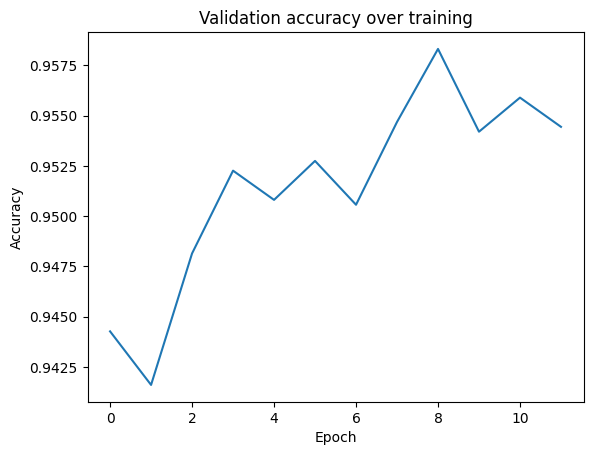

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.99      0.98      0.99       187
                     Pepper__bell___healthy       0.98      1.00      0.99       312
                      Potato___Early_blight       1.00      0.99      0.99       189
                       Potato___Late_blight       0.95      0.96      0.95       198
                           Potato___healthy       0.97      0.91      0.94        35
                      Tomato_Bacterial_spot       0.97      0.96      0.96       439
                        Tomato_Early_blight       0.89      0.80      0.84       189
                         Tomato_Late_blight       0.92      0.92      0.92       384
                           Tomato_Leaf_Mold       0.92      0.97      0.95       181
                  Tomato_Septoria_leaf_spot       0.92      0.94      0.93       366
Tomato_Spider_mites_Two_spotted_spider_mite       0.94      0.94

In [21]:
plt.plot(history['val_acc'])
plt.title('Validation accuracy over training')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=class_names))
print('Confusion matrix (rows = true label, columns = predicted label):')
print(np.array(confusion_matrix(all_labels, all_preds)))

## Step 8: Save the model
Anything saved into `/kaggle/working/` automatically shows up under the notebook's **Output** tab after you run/commit the notebook, where you can download it.

In [22]:
# << CHANGED HERE >> renamed since this model now covers 3 crops, not just tomato
torch.save({'model_state': model.state_dict(), 'class_names': class_names}, '/kaggle/working/multicrop_classifier.pt')
print('Saved to /kaggle/working/multicrop_classifier.pt -- find it in the Output tab after running/committing the notebook.')

Saved to /kaggle/working/multicrop_classifier.pt -- find it in the Output tab after running/committing the notebook.


## Step 9: Test the model on an image
Kaggle notebooks don't have a simple drag-and-drop upload widget like Colab, so the easiest options are:

- **Option A (fastest):** test on a random image already in your validation set (below).
- **Option B:** upload your own photo as a new tiny Kaggle Dataset (Add Data -> Upload), attach it to this notebook the same way you attached PlantVillage, then point `img_path` at its file path under `/kaggle/input/...`.

True label: Tomato__Target_Spot
Prediction: Tomato__Target_Spot
Confidence: 88.33%


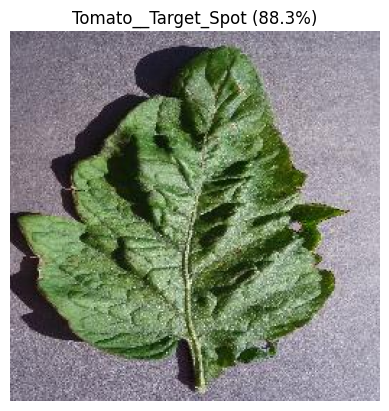

In [23]:
from PIL import Image
import random

# Option A: grab a random image straight from the validation set
sample_idx = random.choice(val_ds.indices)
img_path, true_label_idx = full_dataset.samples[sample_idx]
print('True label:', class_names[true_label_idx])

# --- Option B: uncomment and edit this line instead, if you attached your own image dataset ---
# img_path = '/kaggle/input/your-dataset-name/your_photo.jpg'

img = Image.open(img_path).convert('RGB')
input_tensor = transform(img).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    output = model(input_tensor)
    probs = torch.softmax(output, dim=1)[0]
    pred_idx = probs.argmax().item()

print(f'Prediction: {class_names[pred_idx]}')
print(f'Confidence: {probs[pred_idx]:.2%}')
plt.imshow(img)
plt.axis('off')
plt.title(f'{class_names[pred_idx]} ({probs[pred_idx]:.1%})')
plt.show()

## What you just built
A real transfer-learning image classifier, trained end-to-end on Kaggle's free GPU, that you can test on new images. Next steps from your roadmap:

1. Widen this to more classes/crops once comfortable.
2. Evaluate this same model on **PlantDoc** (real field photos, also on Kaggle -- search 'PlantDoc' in Add Data) and compare accuracy honestly -- this is the 'lab vs field gap' finding from the research report.
3. Move from classification to **detection** (YOLOv8) for Week 7-8 of the roadmap, giving you bounding boxes and severity instead of a single label per image.

If a cell errors out, the most common causes are: the accelerator wasn't set to GPU before running, or the dataset folder names don't match `TARGET_CLASSES` exactly (check the printed class list in Step 2/3 and adjust).

In [24]:
import glob
my_images = glob.glob('/kaggle/input/datasets/jayantmalixcs/test-image/*')
print(my_images)

['/kaggle/input/datasets/jayantmalixcs/test-image/my-tomato-test.png']


Prediction: Tomato_Early_blight
Confidence: 86.61%


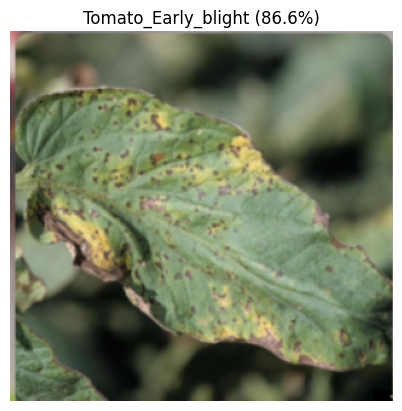

In [25]:
from PIL import Image

img_path = my_images[0]  # or paste the exact path printed above

img = Image.open(img_path).convert('RGB')
input_tensor = transform(img).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    output = model(input_tensor)
    probs = torch.softmax(output, dim=1)[0]
    pred_idx = probs.argmax().item()

print(f'Prediction: {class_names[pred_idx]}')
print(f'Confidence: {probs[pred_idx]:.2%}')
plt.imshow(img)
plt.axis('off')
plt.title(f'{class_names[pred_idx]} ({probs[pred_idx]:.1%})')
plt.show()